In [1]:
# LAB ASSIGNMENT 9
# Cognitive Computing - UCS420
#Q1
import sys
import os
import importlib.util

print("Python Version:", sys.version)
print("Working Directory:", os.getcwd())

libraries = [
    "numpy",
    "pandas",
    "matplotlib",
    "PIL",
    "tensorflow",
    "cv2"
]

print("\nChecking Installed Libraries:\n")

for library in libraries:
    installed = importlib.util.find_spec(library) is not None
    print(library, ":", "Available" if installed else "Not Available")

Python Version: 3.12.12 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 20:16:04) [GCC 11.2.0]
Working Directory: /home/7e61c14b-463b-46bc-9e46-b02866aa5c25

Checking Installed Libraries:

numpy : Available
pandas : Available
matplotlib : Available
PIL : Available
tensorflow : Available
cv2 : Available


In [2]:
!which tesseract

/usr/bin/tesseract


In [3]:
import importlib.util

print("Pytesseract:",
      importlib.util.find_spec("pytesseract") is not None)

Pytesseract: False


In [4]:
# Import required libraries

import os
import re
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps, ImageEnhance
from io import BytesIO

print("All libraries imported successfully!")

All libraries imported successfully!


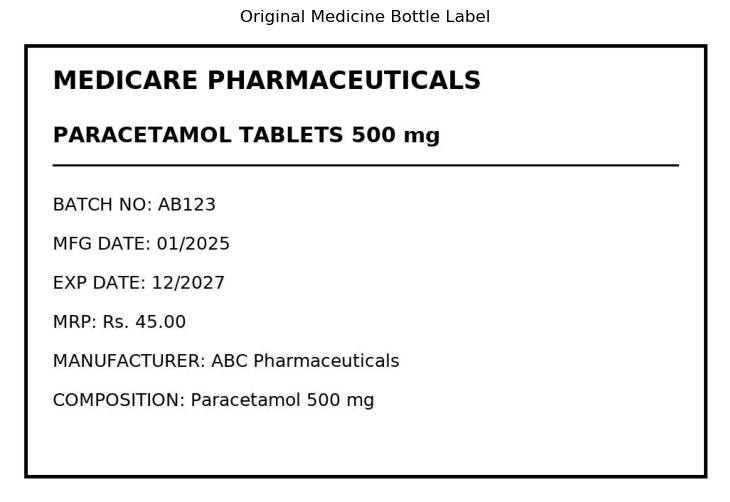

In [5]:
image_path = "medicine.jpg"

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.title("Original Medicine Bottle Label")
plt.axis("off")
plt.show()

In [6]:
medicine.jpg

NameError: name 'medicine' is not defined

In [ ]:
from PIL import Image, ImageDraw, ImageFont

# Create a white image
img = Image.new("RGB", (1000, 650), "white")
draw = ImageDraw.Draw(img)

# Add medicine label text
draw.rectangle((20, 20, 980, 630), outline="black", width=5)

draw.text((60, 50), "MEDICARE PHARMACEUTICALS",
          fill="black", font=ImageFont.truetype(
              "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 35))

draw.text((60, 130), "PARACETAMOL TABLETS 500 mg",
          fill="black", font=ImageFont.truetype(
              "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 30))

draw.line((60, 190, 940, 190), fill="black", width=3)

details = [
    "BATCH NO: AB123",
    "MFG DATE: 01/2025",
    "EXP DATE: 12/2027",
    "MRP: Rs. 45.00",
    "MANUFACTURER: ABC Pharmaceuticals",
    "COMPOSITION: Paracetamol 500 mg"
]

font = ImageFont.truetype(
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 25
)

y = 230

for line in details:
    draw.text((60, y), line, fill="black", font=font)
    y += 55

# Save image
img.save("medicine.jpg")

print("Sample medicine label created successfully!")

In [ ]:
image_path = "medicine.jpg"

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(12, 7))
plt.imshow(image)
plt.title("Sample Medicine Bottle Label")
plt.axis("off")
plt.show()

In [ ]:
# Convert image to grayscale
gray_image = ImageOps.grayscale(image)

# Enhance contrast
enhancer = ImageEnhance.Contrast(gray_image)
processed_image = enhancer.enhance(2.0)

# Display preprocessed image
plt.figure(figsize=(10, 6))
plt.imshow(processed_image, cmap="gray")
plt.title("Preprocessed Medicine Label")
plt.axis("off")
plt.show()

In [ ]:
# Convert processed image into bytes
image_bytes = BytesIO()
processed_image.save(image_bytes, format="PNG")

# Perform OCR
result = subprocess.run(
    ["tesseract", "stdin", "stdout", "--psm", "6"],
    input=image_bytes.getvalue(),
    capture_output=True
)

# Extract recognized text
extracted_text = result.stdout.decode("utf-8")

print("EXTRACTED MEDICINE LABEL TEXT")
print("--------------------------------")
print(extracted_text)

In [ ]:
def extract_information(text):

    information = {}

    patterns = {
        "Medicine Name": r"(PARACETAMOL.*?mg)",
        "Batch Number": r"BATCH\s*NO\s*:\s*([A-Z0-9]+)",
        "Manufacturing Date": r"MFG\s*DATE\s*:\s*([0-9/]+)",
        "Expiry Date": r"EXP\s*DATE\s*:\s*([0-9/]+)",
        "MRP": r"MRP\s*:\s*(?:Rs\.?\s*)?([0-9.]+)",
        "Manufacturer": r"MANUFACTURER\s*:\s*(.*)",
        "Composition": r"COMPOSITION\s*:\s*(.*)"
    }

    for field, pattern in patterns.items():

        match = re.search(
            pattern,
            text,
            re.IGNORECASE
        )

        information[field] = (
            match.group(1).strip()
            if match else "Not Found"
        )

    return information


medicine_info = extract_information(extracted_text)

for key, value in medicine_info.items():
    print(key, ":", value)

In [ ]:
df = pd.DataFrame(
    list(medicine_info.items()),
    columns=["Medicine Information", "Extracted Value"]
)

display(df)

In [ ]:
df.to_csv("medicine_information.csv", index=False)

print("Medicine information saved successfully!")

In [ ]:
from datetime import datetime

expiry = medicine_info["Expiry Date"]

expiry_date = datetime.strptime(expiry, "%m/%Y")

current_date = datetime.now()

if expiry_date < current_date:
    print("WARNING: This medicine has expired!")
else:
    print("Medicine is not expired.")
    print("Expiry Date:", expiry)

In [ ]:
#Q2
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("TensorFlow Successfully Loaded!")

In [ ]:
%pip install --no-cache-dir opencv-python-headless

In [ ]:
import cv2

print("OpenCV version:", getattr(cv2, "__version__", "Unknown"))
print("Loaded from:", cv2.__file__)
print("CascadeClassifier exists:",
      hasattr(cv2, "CascadeClassifier"))
print("Available face-related functions:",
      [x for x in dir(cv2) if "Cascade" in x or "face" in x.lower()][:20])

In [ ]:
%pip uninstall -y opencv-python-headless

In [2]:
%pip install --no-cache-dir opencv-python-headless==4.11.0.86

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 180.7 MB/s  0:00:0080.4 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
import cv2

print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("Face detector loaded:", not face_cascade.empty())

OpenCV Version: 4.11.0
CascadeClassifier: True
Face detector loaded: True


In [4]:
%pip list | grep -i oimport cv2
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("All libraries ready!")pencv

opencv-python-headless            4.11.0.86
Note: you may need to restart the kernel to use updated packages.


In [5]:
import cv2
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("All libraries ready!")

I0000 00:00:1795257712.920229    1031 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795257712.984511    1031 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795257715.181874    1031 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


OpenCV: 4.11.0
TensorFlow: 2.21.0
NumPy: 2.5.4
All libraries ready!


In [6]:
emotion_labels = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

print("Emotion categories:")
for i, emotion in enumerate(emotion_labels):
    print(i, "-", emotion)

Emotion categories:
0 - Angry
1 - Disgust
2 - Fear
3 - Happy
4 - Sad
5 - Surprise
6 - Neutral


In [ ]:
%pip install -q huggingface_hub

In [5]:
import requests

url = "https://huggingface.co"

try:
    r = requests.get(url, timeout=20)
    print("Status:", r.status_code)
    print("Hugging Face accessible:", r.status_code == 200)
except Exception as e:
    print(type(e).__name__, e)

Status: 200
Hugging Face accessible: True


In [8]:
import os

print("Current folder:", os.getcwd())
print("\nFiles available:")
print(os.listdir())

Current folder: /home/7e61c14b-463b-46bc-9e46-b02866aa5c25

Files available:
['.local', '.jupyter', '.pythonstartup.py', 'employees_modified.csv', '.cache', '.ipython', 'Untitled.ipynb', 'README.ipynb', '1024170366_faq_data.csv', 'Untitled2.ipynb', 'nltk_data', '.vimrc', 'COGNITIVE_Assignment1.ipynb', 'anaconda_projects', 'COGNITIVE_Assignment4.ipynb', '.anaconda', '.conda', 'COGNITIVE_Assignment6.ipynb', 'Untitled1.ipynb', 'medicine_information.csv', '.npm', 'COGNITIVE_Assignment5.ipynb', '.virtualenvs', '.gitconfig', '.ipynb_checkpoints', 'Iris.csv', '.keras', 'medicine.jpg', '.config', 'COGNITIVE_Assignment8.ipynb', '.profile', 'COGNITIVE_Assignment9.ipynb', 'COGNITIVE_Assignment3.ipynb', '.bashrc']


In [10]:
import os

print("Model file exists:",
      os.path.exists("finalfacialemotionmodel.keras"))

print(os.listdir())

Model file exists: True
['.local', '.jupyter', '.pythonstartup.py', 'employees_modified.csv', '.cache', '.ipython', 'Untitled.ipynb', 'README.ipynb', '1024170366_faq_data.csv', 'Untitled2.ipynb', 'nltk_data', 'finalfacialemotionmodel.keras', '.vimrc', 'COGNITIVE_Assignment1.ipynb', 'anaconda_projects', 'COGNITIVE_Assignment4.ipynb', '.anaconda', '.conda', 'COGNITIVE_Assignment6.ipynb', 'Untitled1.ipynb', 'medicine_information.csv', '.npm', 'COGNITIVE_Assignment5.ipynb', '.virtualenvs', '.gitconfig', '.ipynb_checkpoints', 'Iris.csv', '.keras', 'medicine.jpg', '.config', 'COGNITIVE_Assignment8.ipynb', '.profile', 'COGNITIVE_Assignment9.ipynb', 'COGNITIVE_Assignment3.ipynb', '.bashrc']


In [13]:
from tensorflow.keras.models import load_model

emotion_model = load_model(
    "finalfacialemotionmodel.keras",
    compile=False
)

print("Pretrained emotion model loaded successfully!")
print("Input shape:", emotion_model.input_shape)
print("Output shape:", emotion_model.output_shape)

Pretrained emotion model loaded successfully!
Input shape: (None, 48, 48, 1)
Output shape: (None, 7)


In [14]:
import os

print(os.path.exists("test_face.jpg"))

False


In [15]:
import os

images = [f for f in os.listdir()
          if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

print(images)

['medicine.jpg', 'Smiling Woman with Wavy Dark Hair.png']


Detected Emotion: Happy
Confidence: 89.95 %


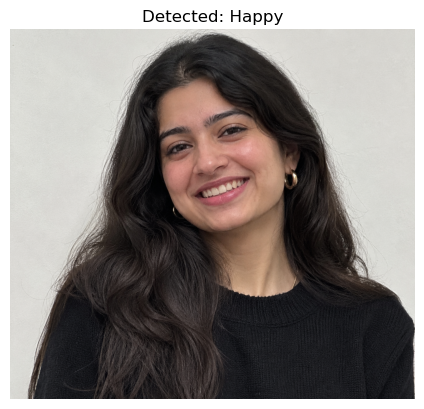

In [16]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Emotion labels in the model's output order
emotion_labels = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

# Load uploaded image
image_path = "Smiling Woman with Wavy Dark Hair.png"
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError("Image could not be loaded!")

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Detect face
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

faces = face_cascade.detectMultiScale(
    gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
)

if len(faces) == 0:
    raise ValueError("No face detected. Try another image.")

# Select largest detected face
x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

face = gray[y:y+h, x:x+w]

# Preprocess image
face = cv2.resize(face, (48, 48))
face = face.astype("float32") / 255.0
face = np.expand_dims(face, axis=(0, -1))

# Predict emotion
predictions = emotion_model.predict(face, verbose=0)

predicted_index = np.argmax(predictions[0])
predicted_emotion = emotion_labels[predicted_index]
confidence = predictions[0][predicted_index] * 100

# Display results
print("Detected Emotion:", predicted_emotion)
print("Confidence:", round(float(confidence), 2), "%")

# Display image
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Detected: {predicted_emotion}")
plt.show()
